# 01 · EDA por edición y conjunto

**Bloque exploratorio** (antes de elegir el tema). EDA de las tablas maestras sin imputar de `00_pipeline_multiedicion_PISA.ipynb` (`data/raw/datos_anuales/`), con los 33 países: primero **cada edición por separado** (2012, 2015, 2018 y 2022) y después **todas juntas**. Sirve para conocer la calidad de los datos: qué falta, dónde y si los huecos son al azar.

Se trabaja con una **vista** de cada tabla (ids, pesos, `PV` y el contexto curado), no con las 1.000+ columnas. Los nulos se dejan tal cual: no se imputa nada. Los nulos de las variables del modelo, ya con el tema elegido, están en `01_EDA_variables_modelo`.

## 0. Configuración

In [1]:
import sys, os
sys.path.append(os.path.abspath('../../'))   # para importar `src`

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import plotly.express as px
import plotly.io as pio
import seaborn as sns
from IPython.display import display, Markdown

from src.pisa_pipeline import (
    EDICIONES_PISA, DOMINIOS, COLUMNAS_CONTEXTO_ESTUDIANTE, COLUMNAS_CONTEXTO_COLEGIO,
    columnas_pv, rutas_datos_anuales, leer_vista_estudiantes, leer_vista_colegios,
)
from src.pisa_estadisticas import centrar_en_grupos, porcentaje_nulos, porcentaje_nulos_por_pais
from src.utils_pisa import establecer_semilla

establecer_semilla()

# Plotly desde CDN: si no, cada figura incrusta la librería entera y el notebook pesa decenas de MB
# pio.renderers.default = 'notebook_connected'
pio.renderers.default = 'vscode' #Usar si existen problemas de renderizado con notebook_connected

Semillas del proyecto establecidas con éxito (seed=42).


In [2]:
EDICIONES = [2012, 2015, 2018, 2022]
RUTA_RAW_BASE = '../../data/raw'                # tablas maestras: data/raw/datos_anuales/
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = 'figuras'                       # figuras del anexo, junto al notebook
UMBRAL_NULOS = 5.0        # % de nulos a partir del cual se revisa el desglose por país
N_MUESTRA_MSNO = 20_000   # alumnos que se muestrean para los gráficos de nulos (la tabla completa es lenta)

pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Vistas de análisis de cada edición, leídas del parquet sin imputar
estudiantes, colegios = {}, {}
for año in EDICIONES:
    ruta_est, ruta_col = rutas_datos_anuales(RUTA_RAW_BASE, año)
    estudiantes[año] = leer_vista_estudiantes(ruta_est)
    colegios[año] = leer_vista_colegios(ruta_col)

pd.DataFrame({
    año: {'alumnos': len(estudiantes[año]), 'centros': len(colegios[año]),
          'países': estudiantes[año]['CNT'].nunique(),
          'cols alumnos (vista)': estudiantes[año].shape[1], 'cols centros (vista)': colegios[año].shape[1]}
    for año in EDICIONES
})

,2012,2015,2018,2022
alumnos,290158,238452,269587,268610
centros,11725,9076,10366,10131
países,33,33,33,33
cols alumnos (vista),40,53,54,57
cols centros (vista),9,10,10,11


## 1. EDA por edición

`eda_edicion(año)` genera, para una edición: dimensiones y % de nulos de cada columna, mapa de nulos por país (columnas con más del 5 % de nulos), patrón de nulos, distribución de los índices, comprobación de que `SENWT` suma 5.000 en cada país, correlaciones y ¿la no-respuesta es señal? (nota del dominio principal de los alumnos con y sin dato, relativa a la media de su país y ponderada con `SENWT`, en los países que tienen la variable). La nota media por país y por centro y el reparto de la varianza de la nota están en `01_EDA_notas_asignatura`.

In [3]:
def eda_edicion(año):
    est, col = estudiantes[año], colegios[año]
    dominio = EDICIONES_PISA[año]['dominio_principal']
    contexto = [c for c in COLUMNAS_CONTEXTO_ESTUDIANTE if c in est.columns]
    contexto_col = [c for c in COLUMNAS_CONTEXTO_COLEGIO if c in col.columns]
    pv_dominio = [c for c in columnas_pv(dominio) if c in est.columns]
    perf = est[pv_dominio].mean(axis=1)   # rendimiento del alumno en el dominio principal

    display(Markdown(f'### PISA {año} (dominio principal: {dominio})'))

    # 1. Dimensiones y nulos
    print(f'{len(est):,} alumnos | {len(col):,} centros | {est["CNT"].nunique()} países')
    nulos_est = porcentaje_nulos(est[contexto])
    nulos_col = porcentaje_nulos(col[contexto_col])
    display(Markdown('**% de nulos de cada columna** (solo las que tienen alguno)'))
    display(pd.concat([nulos_est[nulos_est > 0].rename('% nulos alumnos'),
                       nulos_col[nulos_col > 0].rename('% nulos centros')], axis=1).round(1))

    # 2. % de nulos por país en las columnas con más del UMBRAL_NULOS % de nulos, de alumnos y de centros
    paneles = [(tabla, df, list(nulos[nulos > UMBRAL_NULOS].index))
               for tabla, df, nulos in (('alumnos', est, nulos_est), ('centros', col, nulos_col))]
    paneles = [panel for panel in paneles if panel[2]]
    if paneles:
        columnas_totales = sum(len(columnas) for _, _, columnas in paneles)
        fig, ejes = plt.subplots(1, len(paneles), figsize=(2.5 + 0.7 * columnas_totales, 9), squeeze=False,
                                 gridspec_kw={'width_ratios': [len(columnas) for _, _, columnas in paneles]})
        for eje, (tabla, df, columnas) in zip(ejes[0], paneles):
            por_pais = df[columnas].isna().groupby(df['CNT'].astype(str)).mean().mul(100)
            sns.heatmap(por_pais, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar=False, ax=eje, annot_kws={'fontsize': 7})
            eje.set_title(tabla)
            eje.set_xlabel('')
            eje.set_ylabel('')
            eje.tick_params(axis='x', labelrotation=90)
        fig.suptitle(f'% de nulos por país en las columnas con más del {UMBRAL_NULOS:.0f} % de nulos — PISA {año}')
        plt.tight_layout()
        plt.show()

    # 3. Patrón de nulos (muestra de alumnos)
    muestra = est[contexto].sample(min(N_MUESTRA_MSNO, len(est)))   # semilla fijada con establecer_semilla()
    msno.matrix(muestra, figsize=(14, 4))
    plt.title(f'Matriz de nulos — PISA {año} (muestra)')
    plt.show()
    msno.heatmap(muestra, figsize=(9, 7))
    plt.title(f'Correlación de nulidad — PISA {año}')
    plt.show()
    msno.dendrogram(muestra, figsize=(10, 5))
    plt.title(f'Bloques de nulidad conjunta — PISA {año}')
    plt.show()

    # 4. Distribución de los índices de contexto (HISEI, 0-100, aparte)
    indices = [c for c in contexto if c != 'HISEI']
    n_filas = -(-len(indices) // 4)
    fig, axes = plt.subplots(n_filas, 4, figsize=(16, 3 * n_filas))
    for ax, c in zip(axes.flat, indices):
        est[c].dropna().hist(bins=50, ax=ax)
        ax.set_title(c)
    for ax in axes.flat[len(indices):]:
        ax.axis('off')
    plt.suptitle(f'Índices de contexto — PISA {año}')
    plt.tight_layout()
    plt.show()

    # 5. Comprobación de los pesos: SENWT tiene que sumar 5.000 en cada país, para que todos pesen igual
    sumas = est.groupby(est['CNT'].astype(str))['SENWT'].sum()
    print(f'Comprobación de pesos: SENWT suma entre {sumas.min():.2f} y {sumas.max():.2f} por país (tiene que ser 5.000 en todos)')

    # 6. Correlación entre contexto y rendimiento (media de los PV de cada dominio)
    df_corr = est[contexto].copy()
    for d in DOMINIOS:
        pv = [c for c in columnas_pv(d) if c in est.columns]
        df_corr[d] = est[pv].mean(axis=1)
    corr = df_corr.corr()
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(im, ax=ax, label='correlación de Pearson')
    plt.title(f'Contexto y rendimiento — PISA {año}')
    plt.tight_layout()
    plt.show()

    # 7. ¿La no-respuesta es señal? Nota del dominio principal relativa a la media de su país (con SENWT) de quien
    # tiene el dato frente a quien no, en los países que tienen la variable
    nota_relativa = centrar_en_grupos(est.assign(nota=perf), ['nota'], ['CNT'], peso_col='SENWT')['nota']
    filas = []
    for c in nulos_est[nulos_est > 0].index:
        falta = est[c].isna()
        preguntada = (~falta).groupby(est['CNT']).transform('any')
        con_dato, sin_dato = preguntada & ~falta, preguntada & falta
        if sin_dato.any():
            nota_con = np.average(nota_relativa[con_dato], weights=est.loc[con_dato, 'SENWT'])
            nota_sin = np.average(nota_relativa[sin_dato], weights=est.loc[sin_dato, 'SENWT'])
            filas.append({'variable': c, '% sin dato (países con la variable)': 100 * sin_dato.sum() / preguntada.sum(),
                          'nota_con_dato': nota_con, 'nota_sin_dato': nota_sin, 'diferencia': nota_con - nota_sin})
    if filas:
        display(Markdown(f'**¿La no-respuesta es señal?** Nota de {dominio} relativa a la media del país, de los alumnos con y sin dato de cada columna (países con la variable, ponderado con `SENWT`)'))
        display(pd.DataFrame(filas).set_index('variable').sort_values('diferencia', key=abs, ascending=False).round(1))


### 1.1 PISA 2012

### PISA 2012 (dominio principal: MATH)

290,158 alumnos | 11,725 centros | 33 países


**% de nulos de cada columna** (solo las que tienen alguno)

,% nulos alumnos,% nulos centros
OUTHOURS,35.60,NaN
BELONG,35.00,NaN
DISCLIMA,34.90,NaN
ANXMAT,34.90,NaN
TEACHSUP,34.70,NaN
MATHEFF,34.70,NaN
HISEI_TREND,5.00,NaN
HISEI,4.90,NaN
PAREDINT_TREND,4.00,NaN
PAREDINT,3.20,NaN


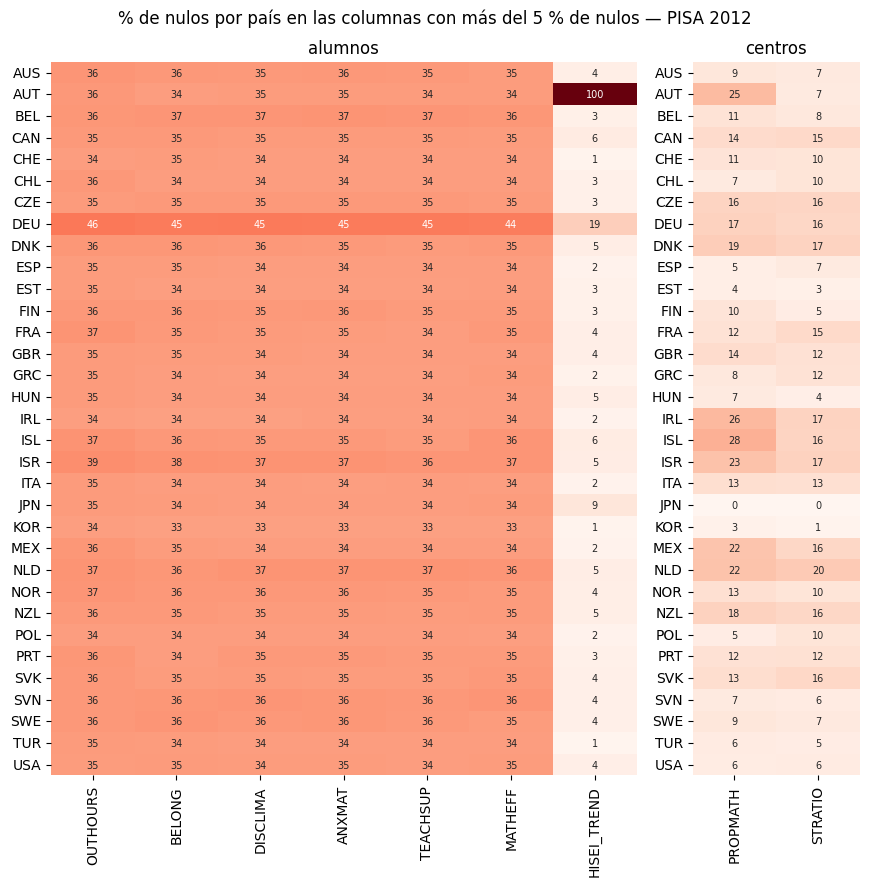

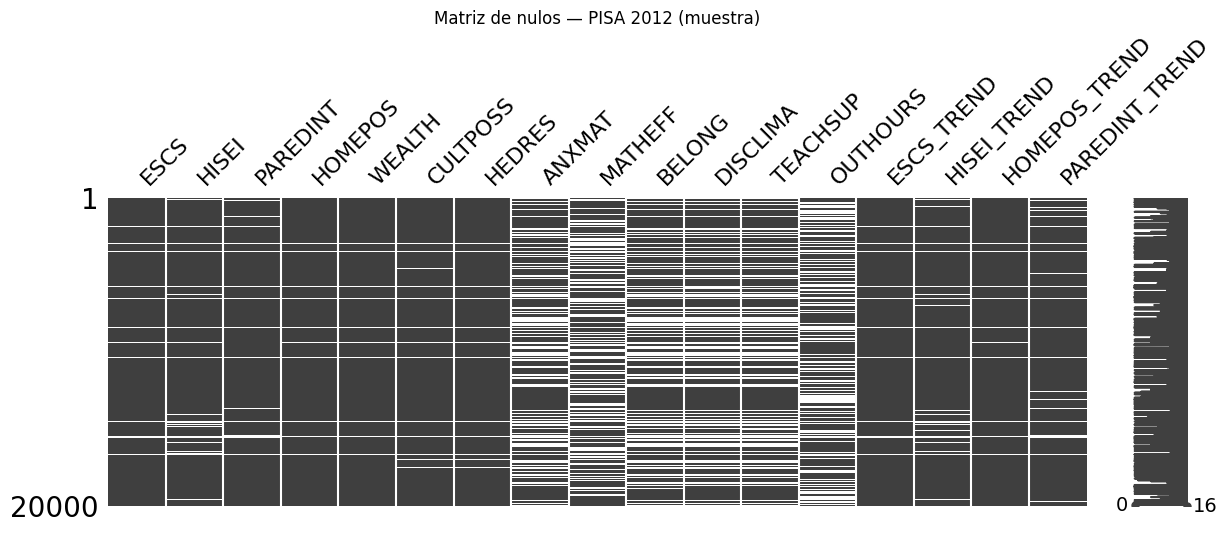

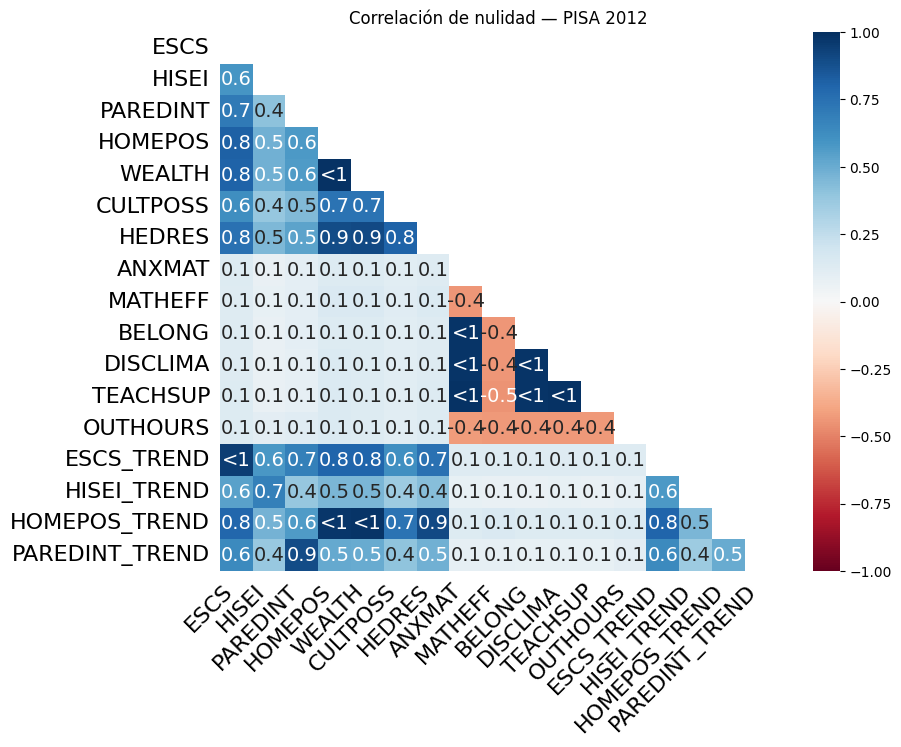

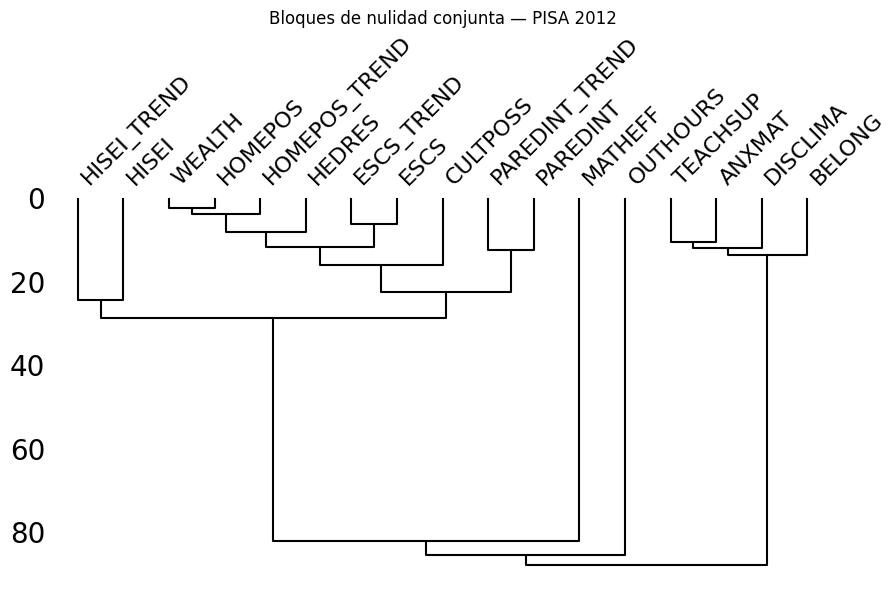

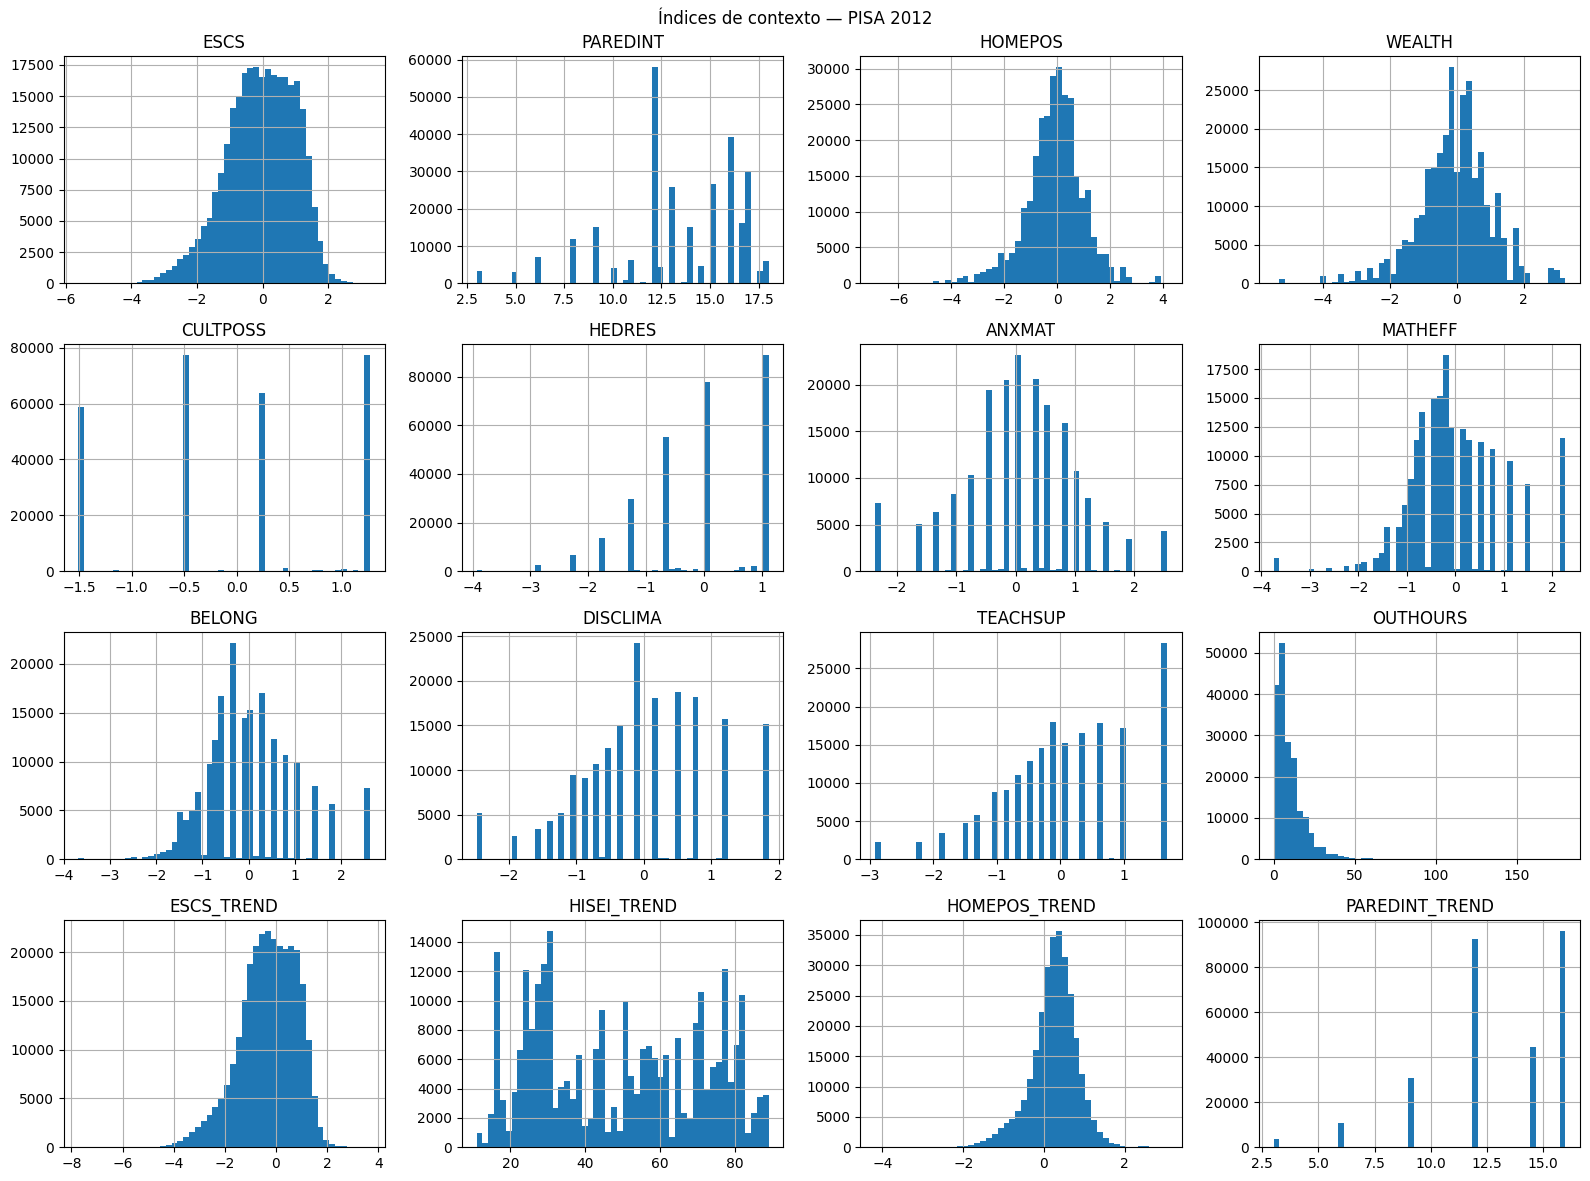

Comprobación de pesos: SENWT suma entre 5000.00 y 5000.00 por país (tiene que ser 5.000 en todos)


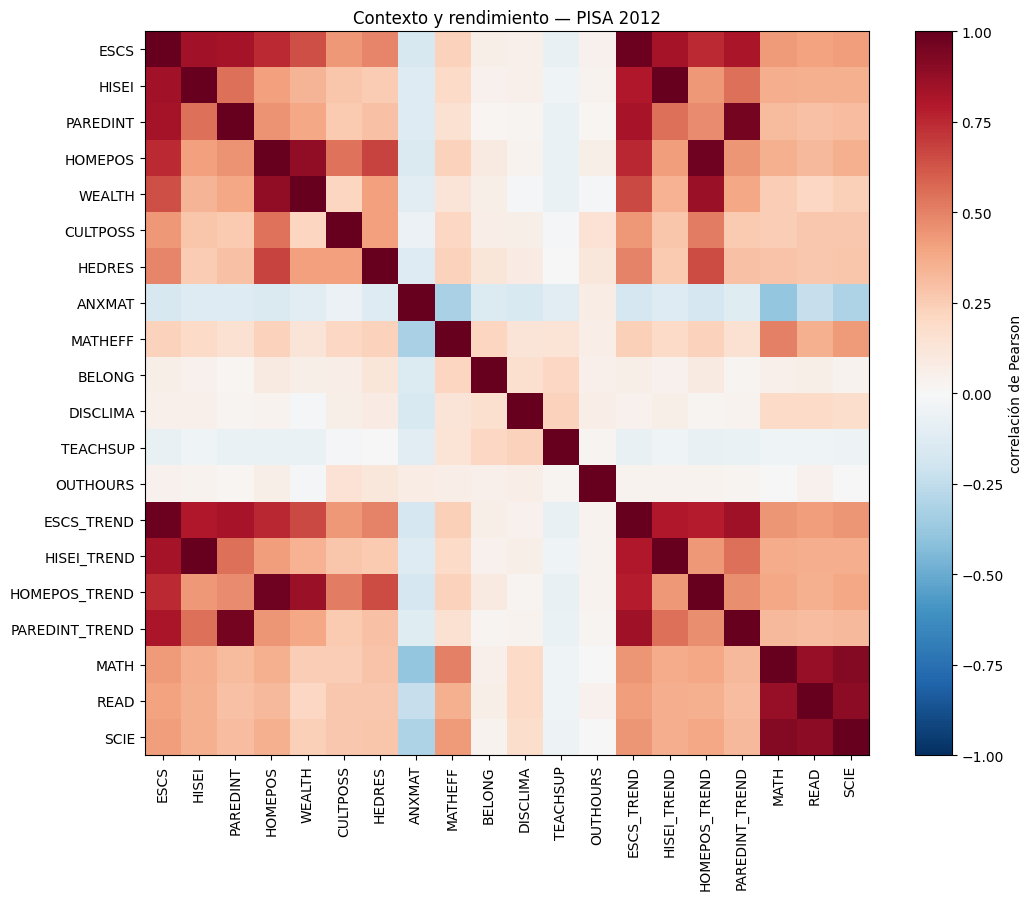

**¿La no-respuesta es señal?** Nota de MATH relativa a la media del país, de los alumnos con y sin dato de cada columna (países con la variable, ponderado con `SENWT`)

,% sin dato (países con la variable),nota_con_dato,nota_sin_dato,diferencia
variable,,,,
CULTPOSS,2.60,2.10,-73.90,76.00
ESCS,1.70,1.40,-67.40,68.80
ESCS_TREND,1.70,1.40,-67.10,68.50
PAREDINT,3.20,2.50,-64.30,66.80
HEDRES,1.50,1.20,-65.60,66.80
HISEI,4.90,3.70,-61.70,65.40
HISEI_TREND,3.50,2.50,-60.80,63.40
PAREDINT_TREND,4.00,2.90,-60.10,63.00
HOMEPOS,1.30,0.90,-60.70,61.60


In [4]:
eda_edicion(2012)

### 1.2 PISA 2015

### PISA 2015 (dominio principal: SCIE)

238,452 alumnos | 9,076 centros | 33 países


**% de nulos de cada columna** (solo las que tienen alguno)

,% nulos alumnos,% nulos centros
OUTHOURS,15.80,NaN
TEACHSUP,14.80,NaN
HISEI,8.70,NaN
HISEI_TREND,7.00,NaN
BELONG,6.00,NaN
PAREDINT_TREND,3.80,NaN
CULTPOSS,3.40,NaN
PAREDINT,3.30,NaN
ESCS,2.30,NaN
ESCS_TREND,2.30,NaN


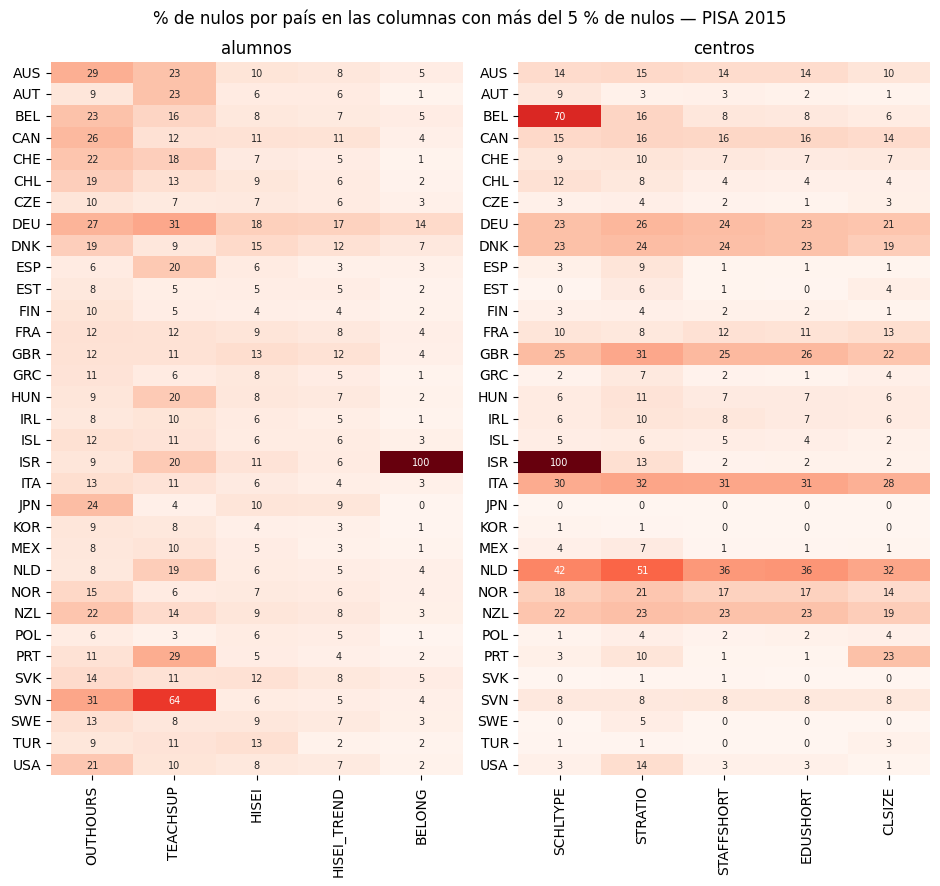

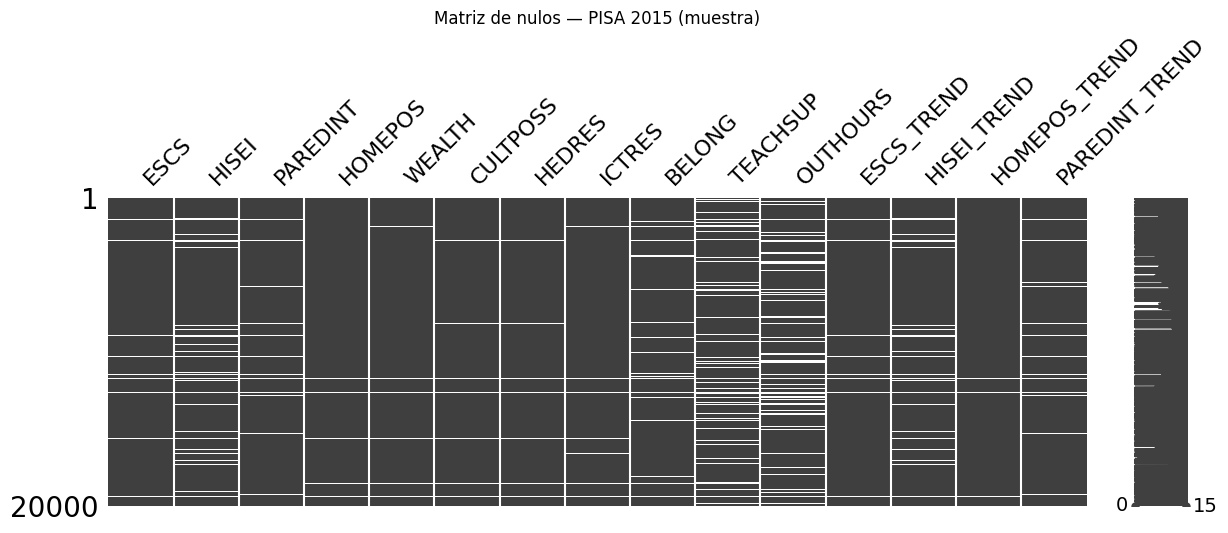

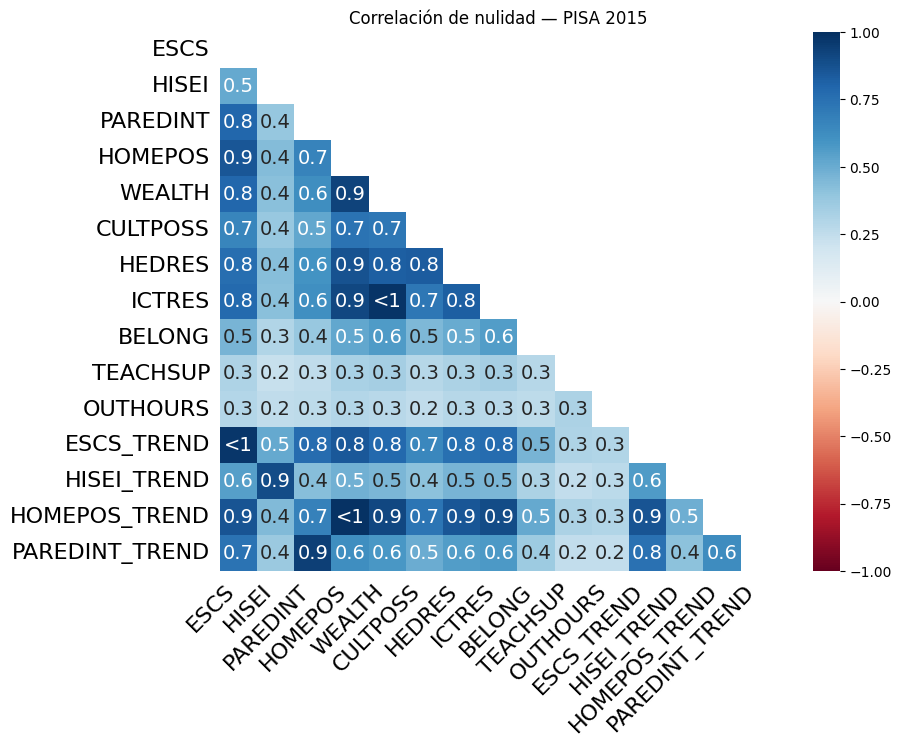

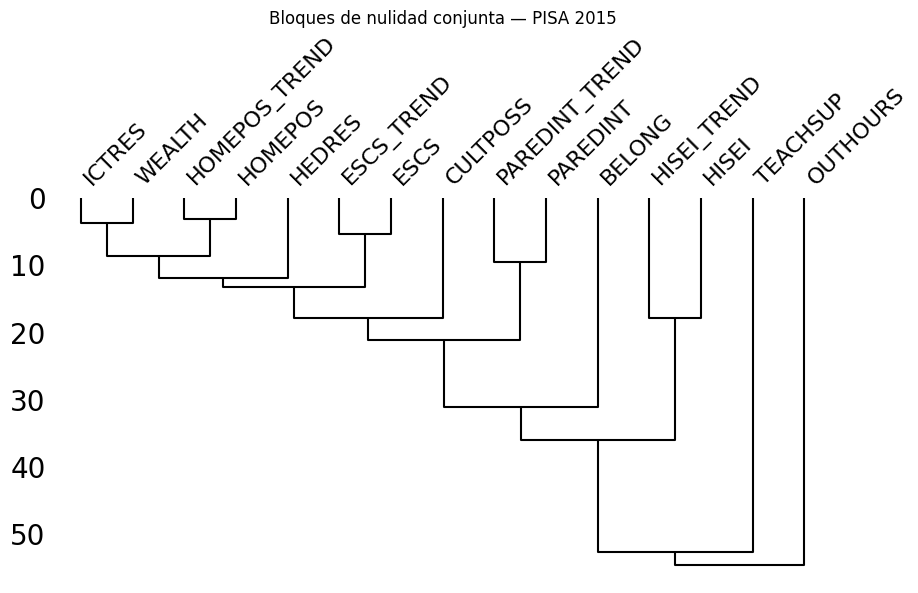

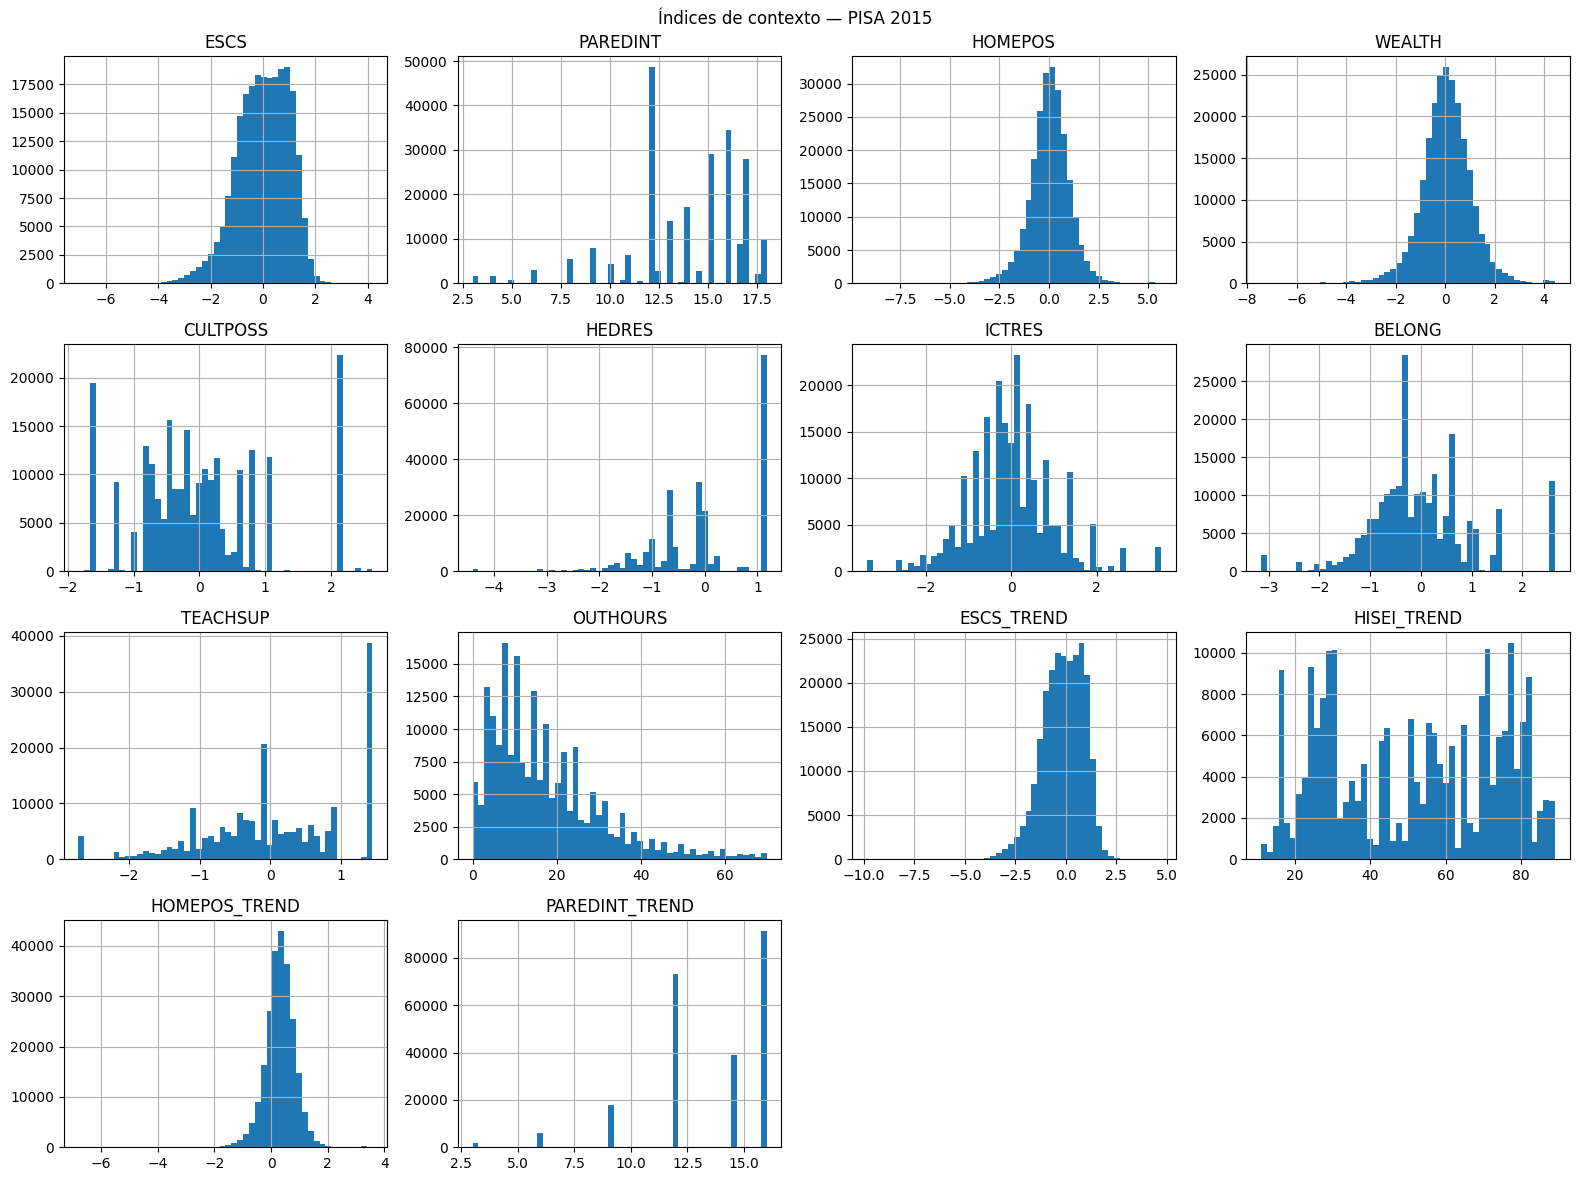

Comprobación de pesos: SENWT suma entre 5000.00 y 5000.00 por país (tiene que ser 5.000 en todos)


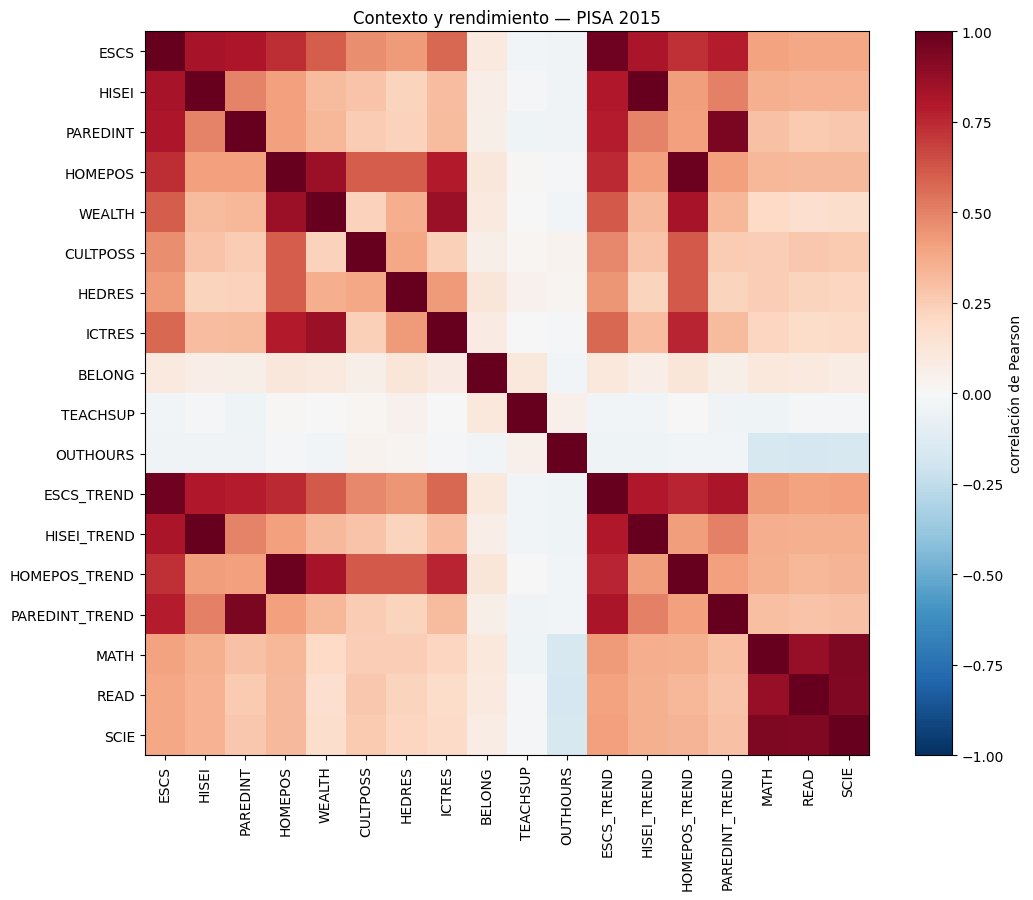

**¿La no-respuesta es señal?** Nota de SCIE relativa a la media del país, de los alumnos con y sin dato de cada columna (países con la variable, ponderado con `SENWT`)

,% sin dato (países con la variable),nota_con_dato,nota_sin_dato,diferencia
variable,,,,
BELONG,3.30,2.60,-79.30,81.90
CULTPOSS,3.40,2.30,-68.10,70.40
HEDRES,2.30,1.40,-65.50,67.00
HISEI,8.70,5.60,-61.20,66.70
HISEI_TREND,7.00,4.30,-61.40,65.70
OUTHOURS,15.80,8.60,-50.20,58.70
ESCS,2.30,1.20,-53.90,55.10
ESCS_TREND,2.30,1.20,-53.40,54.60
PAREDINT,3.30,1.60,-49.60,51.30


In [5]:
eda_edicion(2015)

### 1.3 PISA 2018

### PISA 2018 (dominio principal: READ)

269,587 alumnos | 10,366 centros | 33 países


**% de nulos de cada columna** (solo las que tienen alguno)

,% nulos alumnos,% nulos centros
BEINGBULLIED,24.80,NaN
BELONG,11.90,NaN
TEACHSUP,11.90,NaN
HISEI,8.10,NaN
HISEI_TREND,8.10,NaN
PAREDINT,4.60,NaN
PAREDINT_TREND,4.60,NaN
CULTPOSS,3.90,NaN
DISCLIMA,3.80,NaN
ESCS,3.40,NaN


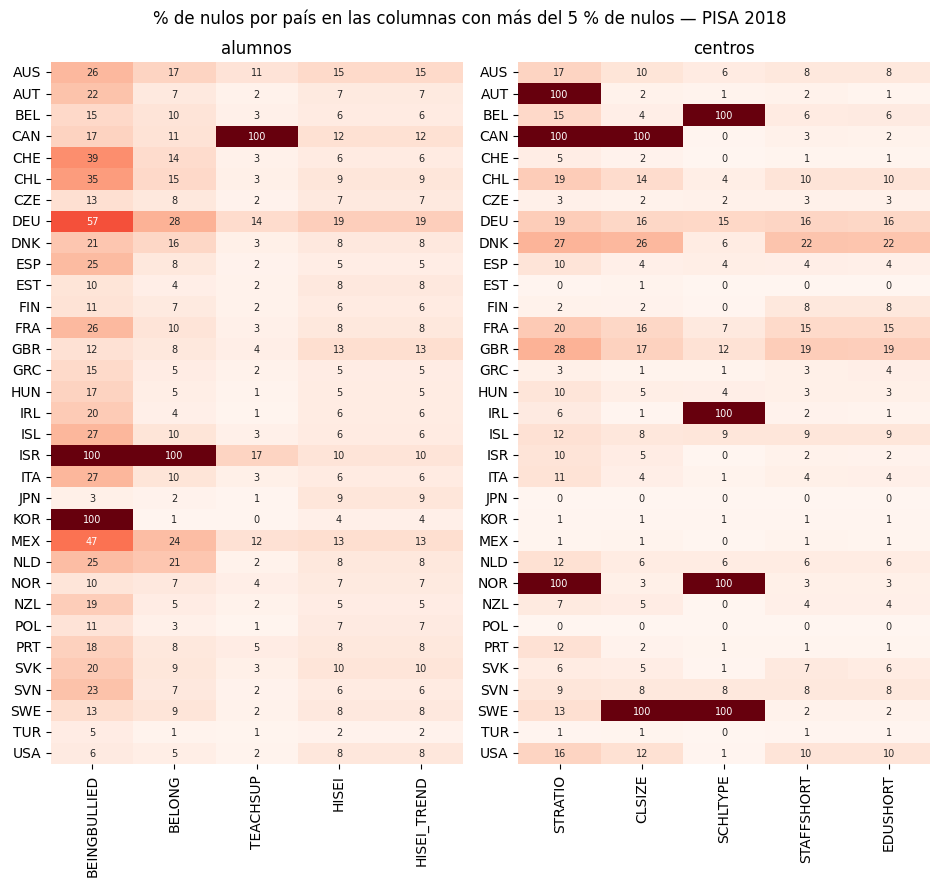

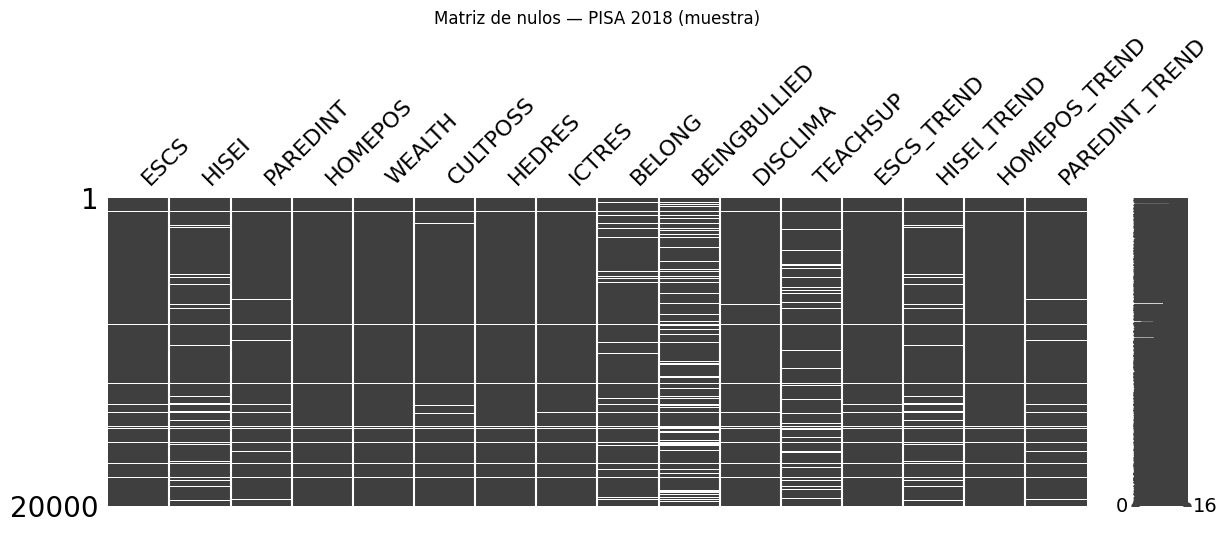

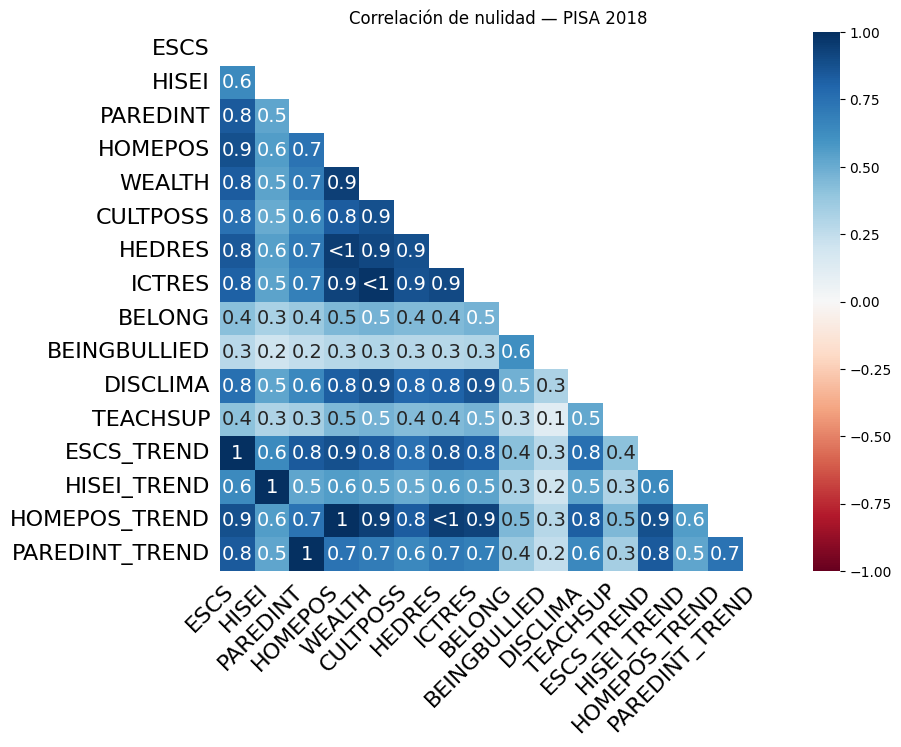

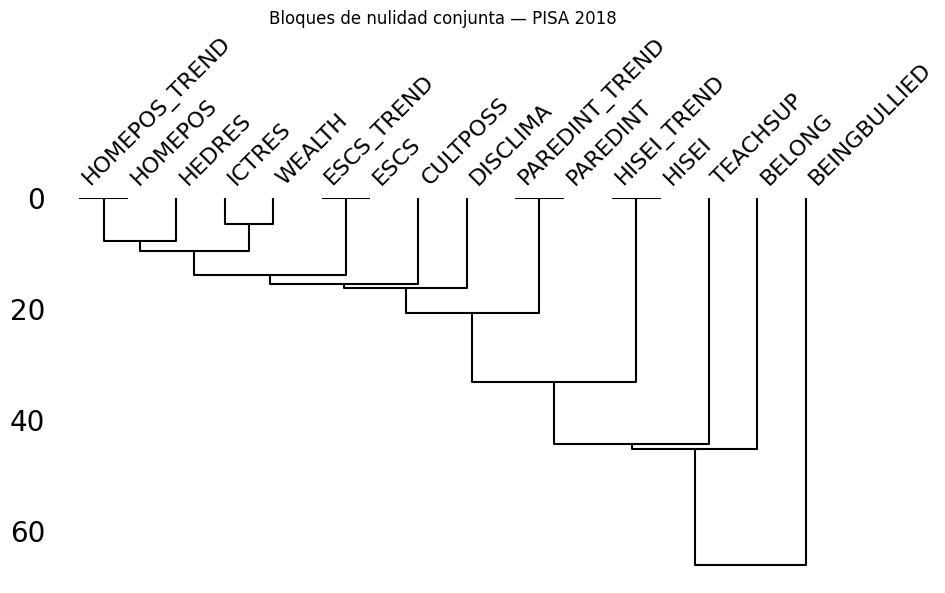

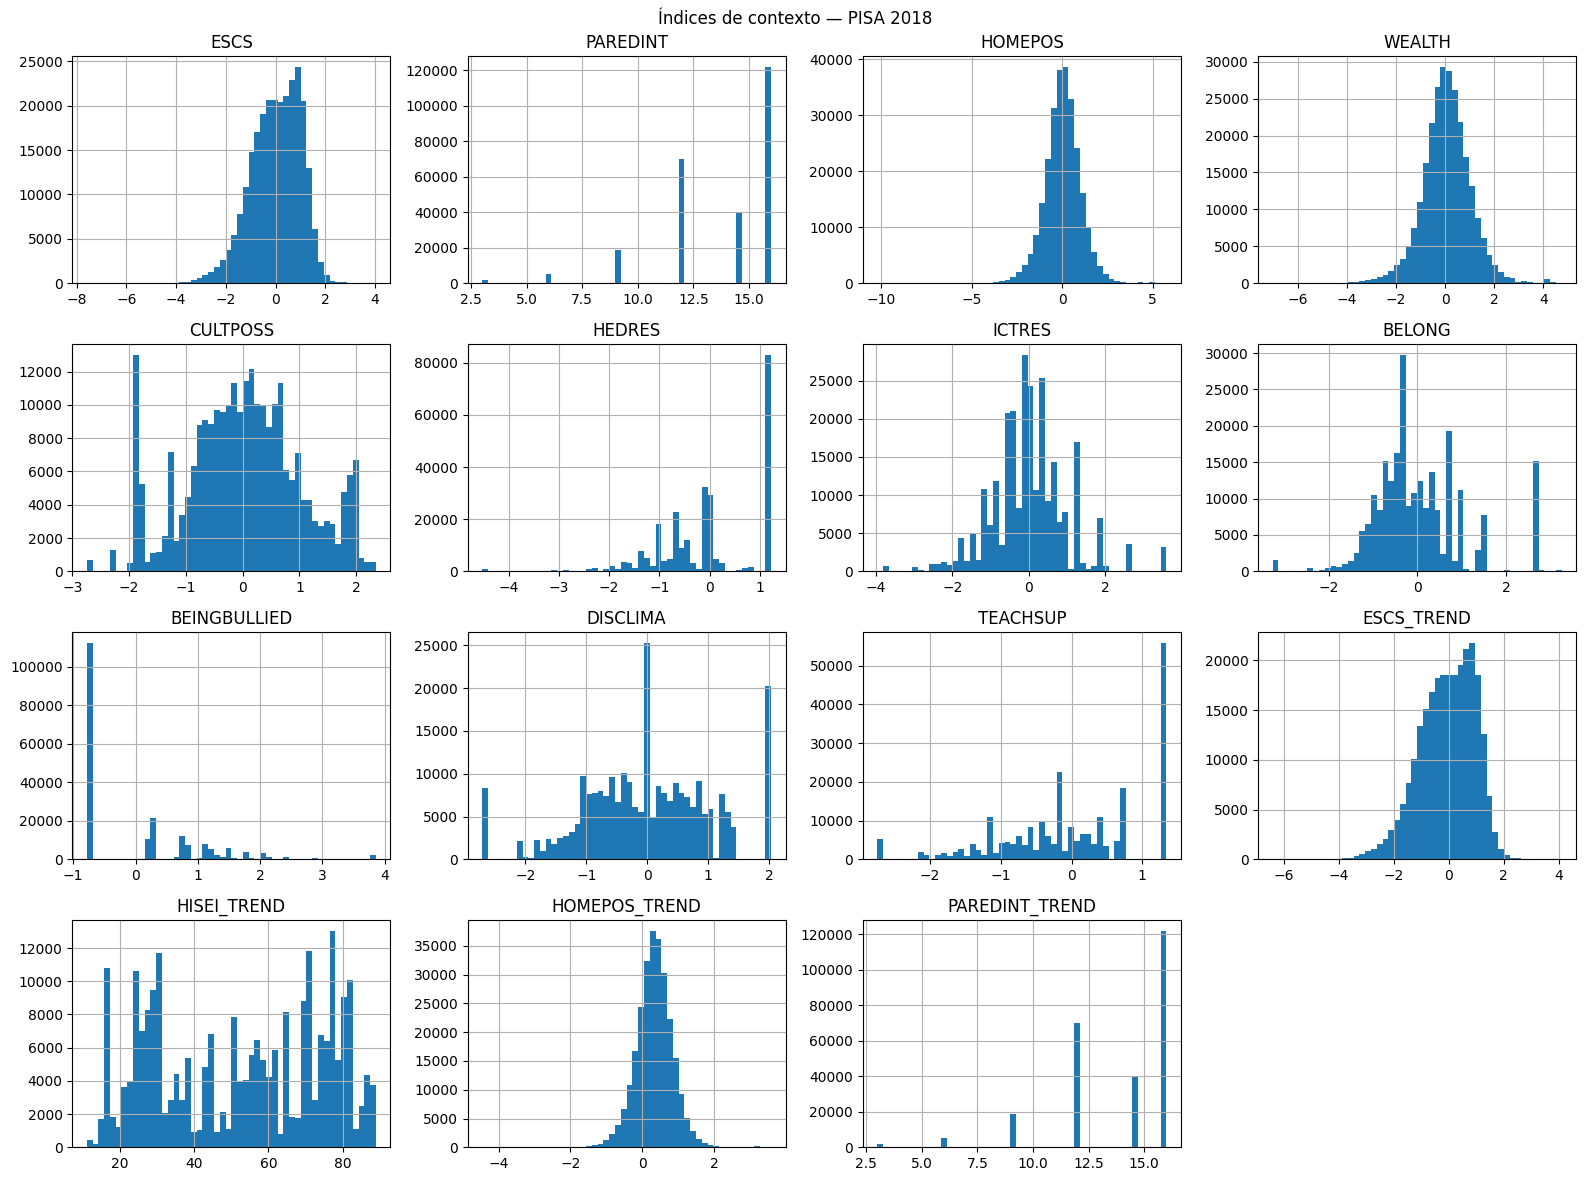

Comprobación de pesos: SENWT suma entre 5000.00 y 5000.00 por país (tiene que ser 5.000 en todos)


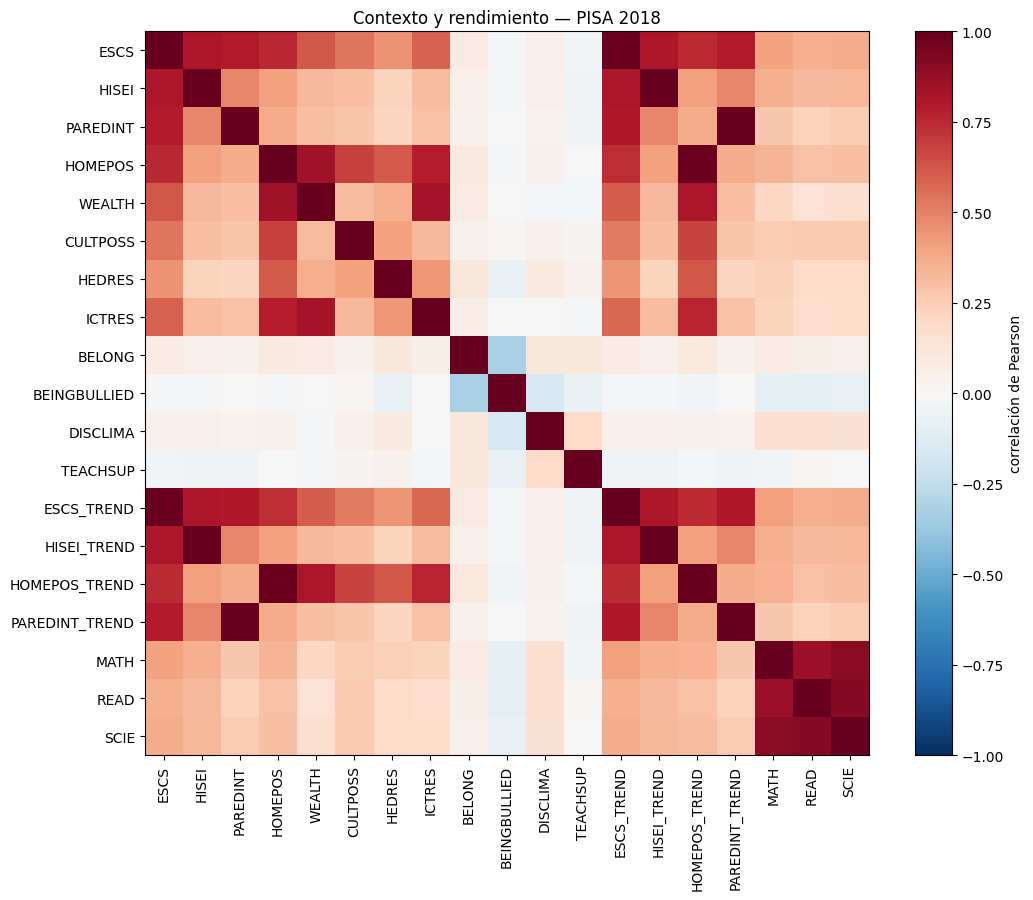

**¿La no-respuesta es señal?** Nota de READ relativa a la media del país, de los alumnos con y sin dato de cada columna (países con la variable, ponderado con `SENWT`)

,% sin dato (países con la variable),nota_con_dato,nota_sin_dato,diferencia
variable,,,,
HISEI,8.10,5.60,-65.20,70.80
HISEI_TREND,8.10,5.60,-65.20,70.80
TEACHSUP,3.80,2.30,-59.70,62.00
BELONG,9.60,5.60,-53.60,59.20
DISCLIMA,3.80,2.10,-56.10,58.20
HEDRES,3.00,1.50,-53.30,54.80
CULTPOSS,3.90,1.90,-48.20,50.20
ESCS_TREND,3.40,1.60,-48.40,49.90
ESCS,3.40,1.60,-48.40,49.90


In [6]:
eda_edicion(2018)

### 1.4 PISA 2022

### PISA 2022 (dominio principal: MATH)

268,610 alumnos | 10,131 centros | 33 países


**% de nulos de cada columna** (solo las que tienen alguno)

,% nulos alumnos,% nulos centros
ICTRES,58.70,NaN
ICTDISTR,43.80,NaN
ICTWKEND,35.00,NaN
ICTWKDY,33.10,NaN
TEACHSUP,16.60,NaN
ANXMAT,15.10,NaN
MATHEFF,12.50,NaN
HISEI,10.40,NaN
HISEI_TREND,10.40,NaN
BELONG,7.90,NaN


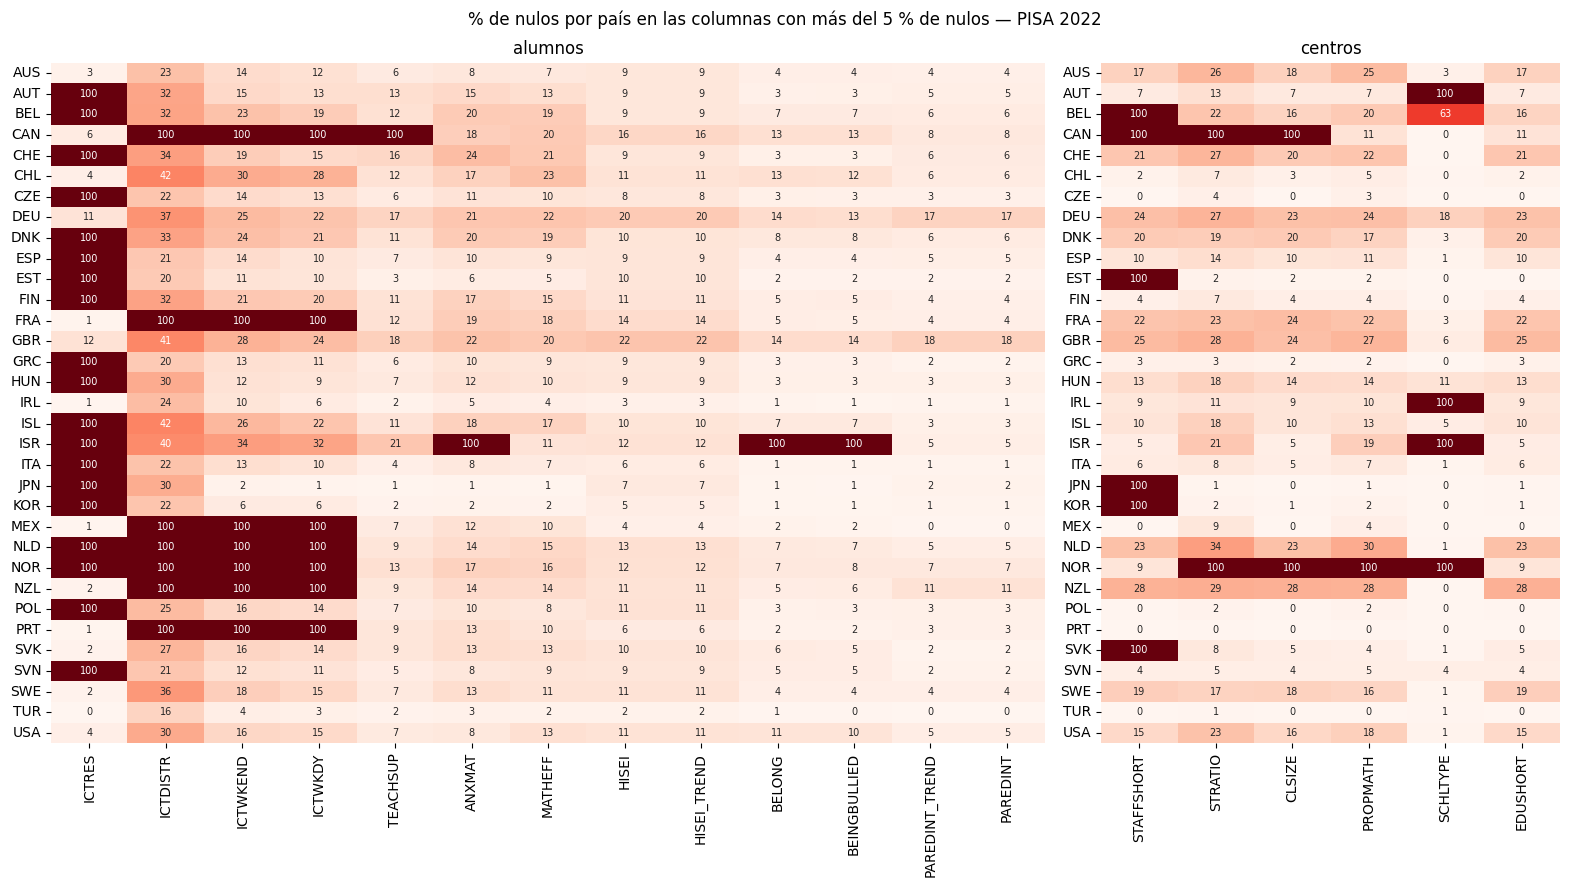

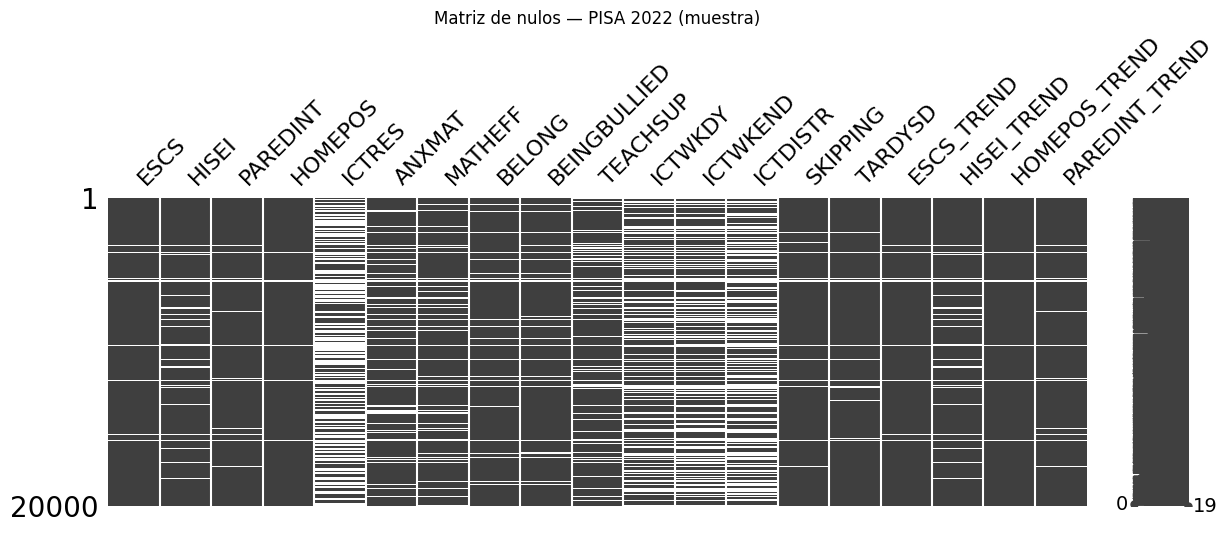

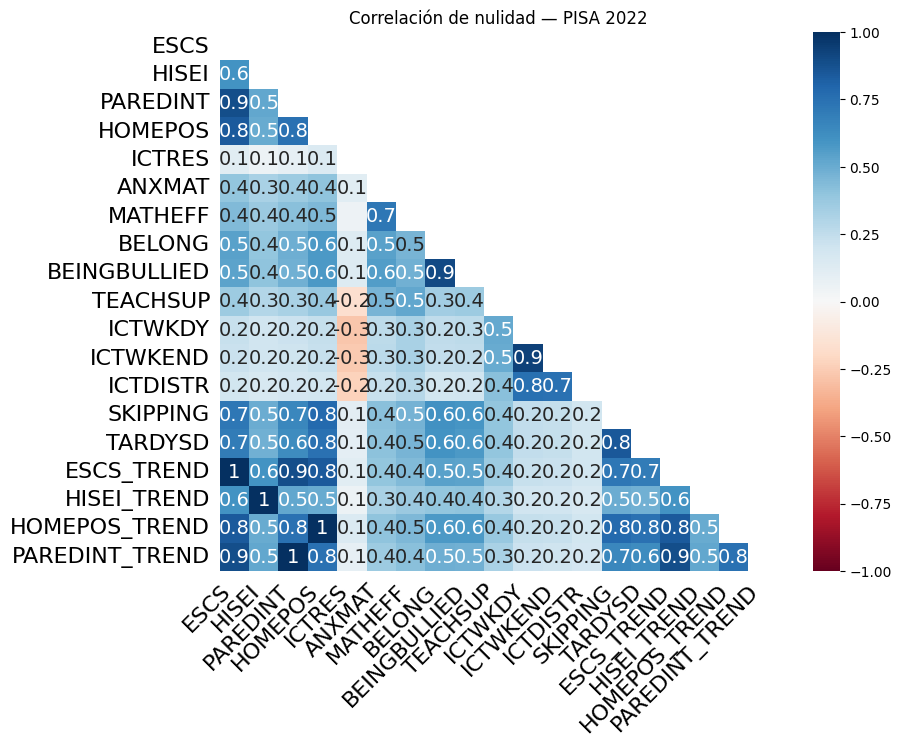

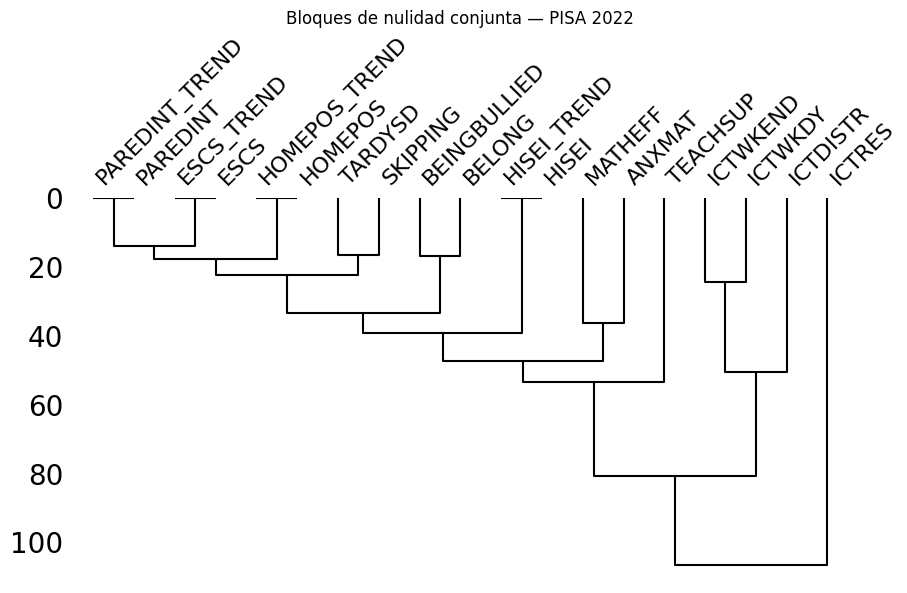

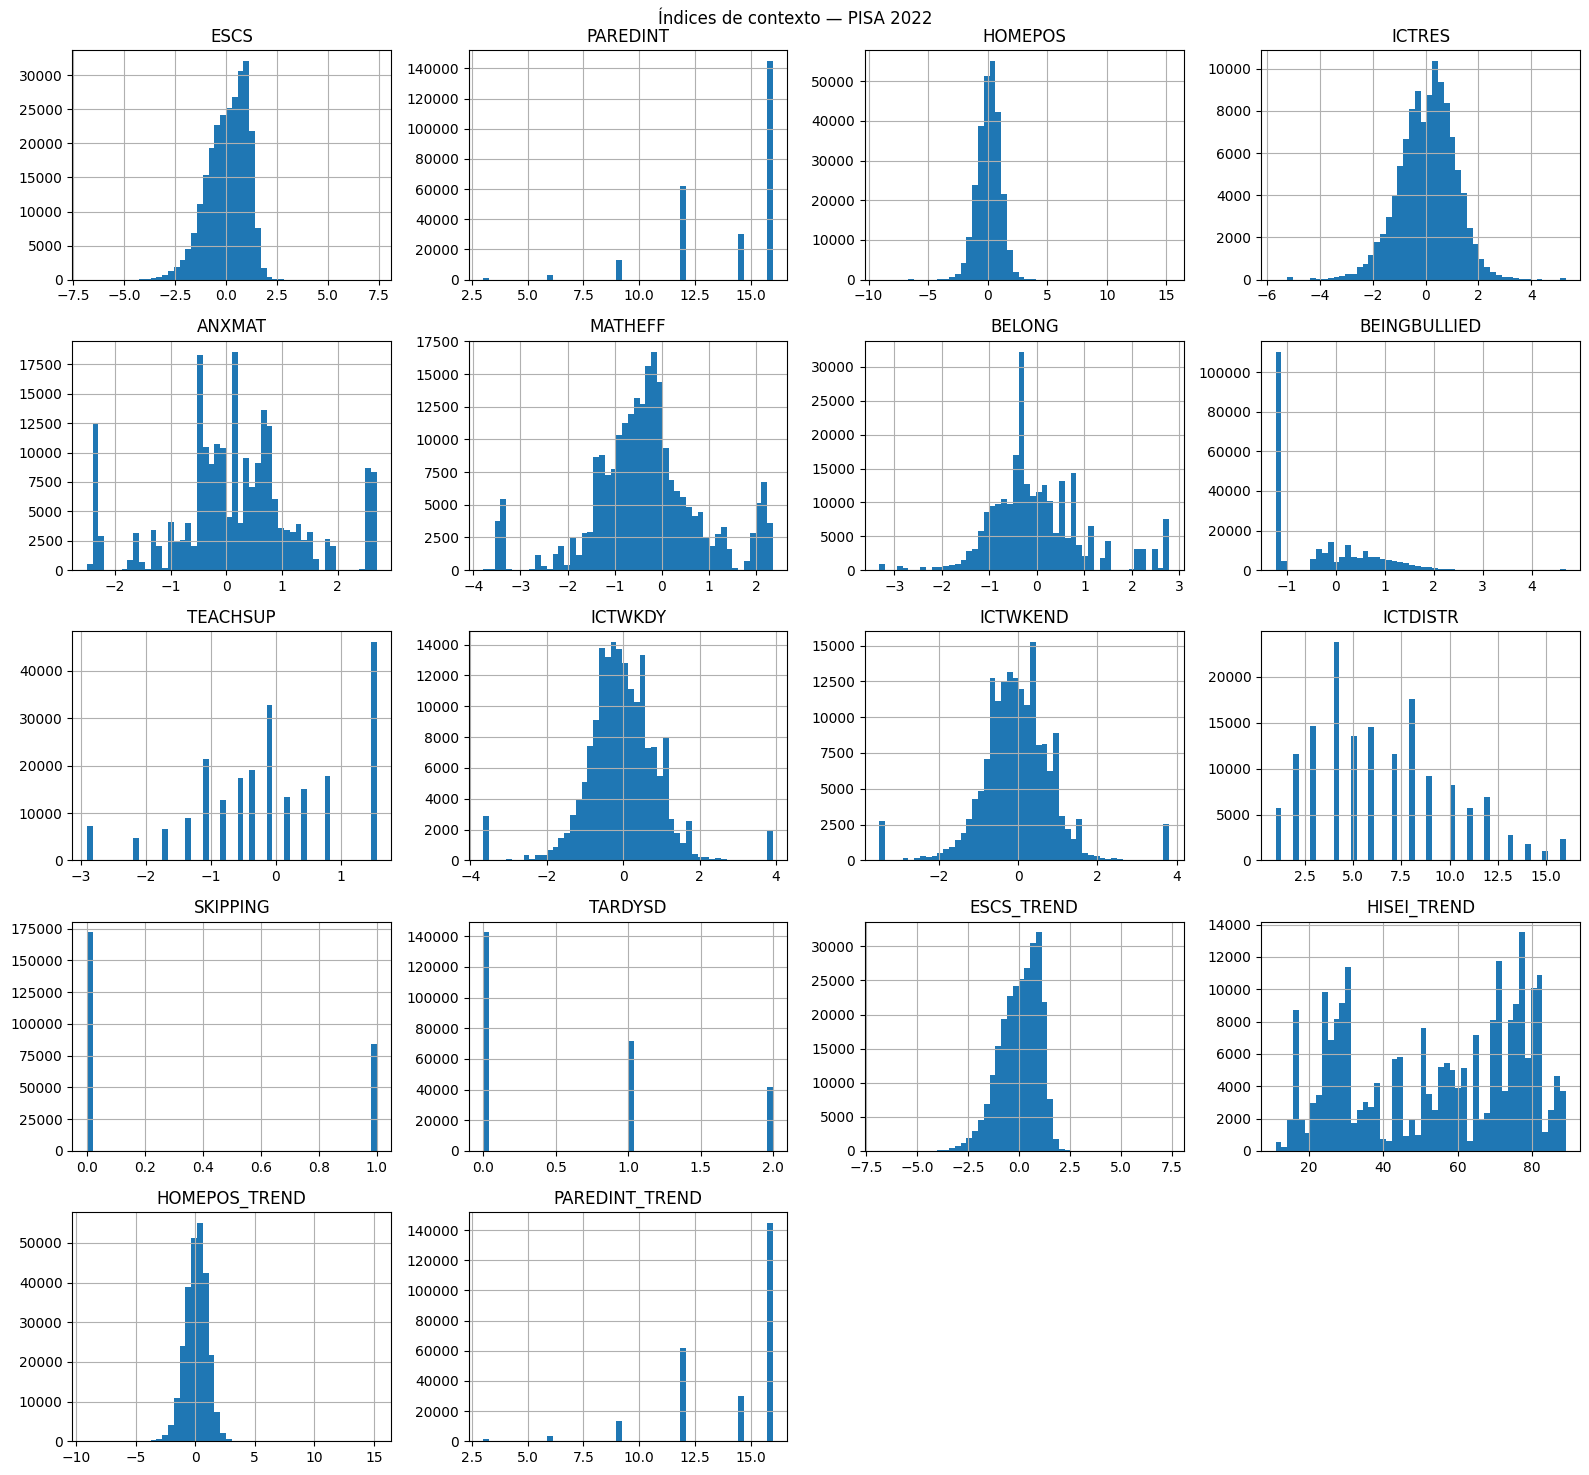

Comprobación de pesos: SENWT suma entre 5000.00 y 5000.01 por país (tiene que ser 5.000 en todos)


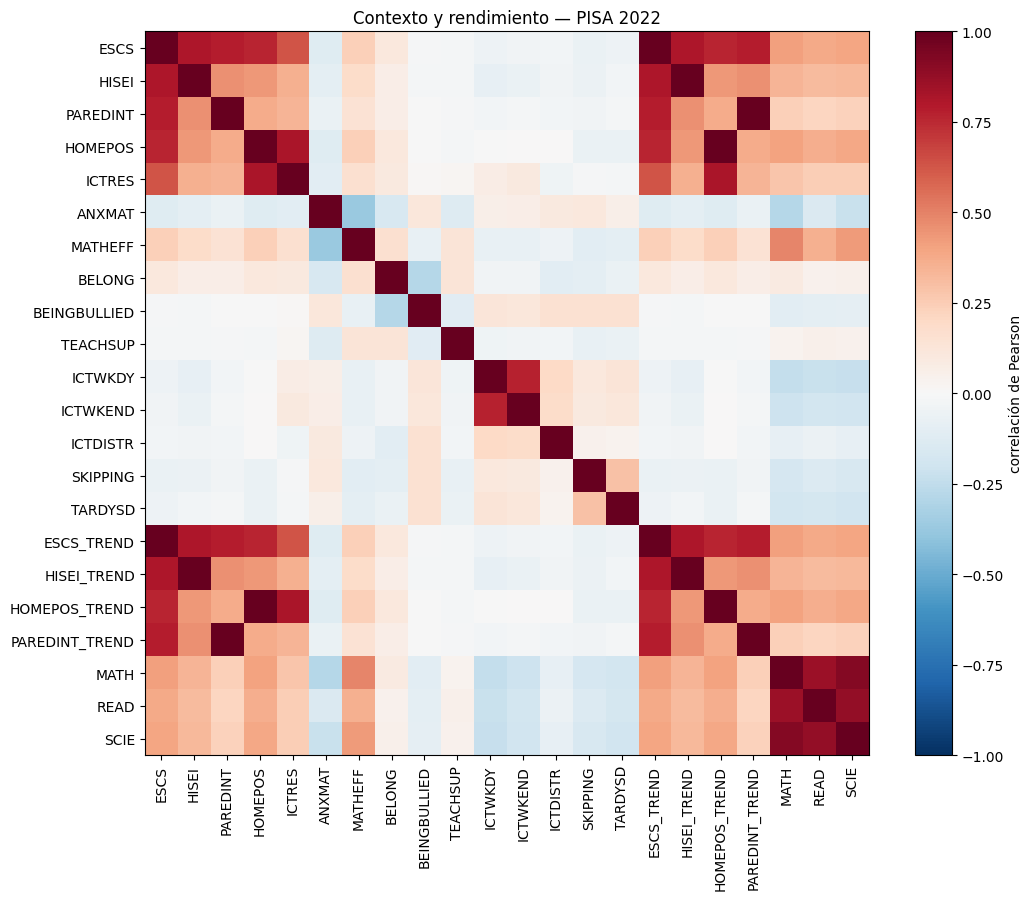

**¿La no-respuesta es señal?** Nota de MATH relativa a la media del país, de los alumnos con y sin dato de cada columna (países con la variable, ponderado con `SENWT`)

,% sin dato (países con la variable),nota_con_dato,nota_sin_dato,diferencia
variable,,,,
BELONG,5.70,3.50,-60.90,64.40
BEINGBULLIED,5.60,3.50,-60.90,64.40
TEACHSUP,8.80,5.30,-52.80,58.10
MATHEFF,12.50,7.30,-50.80,58.10
TARDYSD,4.80,2.50,-55.40,57.90
HISEI,10.40,5.80,-51.80,57.60
HISEI_TREND,10.40,5.80,-51.80,57.60
SKIPPING,4.50,2.40,-54.60,57.00
ICTWKDY,14.20,7.60,-43.60,51.20


In [7]:
eda_edicion(2022)

## 2. EDA conjunto

Comparación entre las cuatro ediciones.

### 2.1 Nulos por columna y edición

`NaN` = la columna no existe en esa edición. En 2012, `BELONG`, `ANXMAT`, `MATHEFF`, `TEACHSUP`, `DISCLIMA` y `OUTHOURS` tienen ~35 % de nulos por la rotación de cuestionarios (cada alumno responde 2 de 3 bloques).

In [8]:
ctx_est = [c for c in COLUMNAS_CONTEXTO_ESTUDIANTE]
resumen_nulos = pd.DataFrame({
    año: porcentaje_nulos(estudiantes[año][[c for c in ctx_est if c in estudiantes[año].columns]])
    for año in EDICIONES
}).sort_values(by=EDICIONES[-1], ascending=False)
resumen_nulos.round(1)

,2012,2015,2018,2022
ICTRES,NaN,2.20,3.10,58.70
ICTDISTR,NaN,NaN,NaN,43.80
ICTWKEND,NaN,NaN,NaN,35.00
ICTWKDY,NaN,NaN,NaN,33.10
TEACHSUP,34.70,14.80,11.90,16.60
ANXMAT,34.90,NaN,NaN,15.10
MATHEFF,34.70,NaN,NaN,12.50
HISEI_TREND,5.00,7.00,8.10,10.40
HISEI,4.90,8.70,8.10,10.40
BELONG,35.00,6.00,11.90,7.90


### 2.2 Nulos en colegios

In [9]:
resumen_nulos_colegios = pd.DataFrame({
    año: porcentaje_nulos(colegios[año][[c for c in COLUMNAS_CONTEXTO_COLEGIO if c in colegios[año].columns]])
    for año in EDICIONES
}).sort_values(by=EDICIONES[-1], ascending=False)
resumen_nulos_colegios.round(1)

,2012,2015,2018,2022
STAFFSHORT,NaN,10.90,5.90,28.80
STRATIO,11.20,13.80,22.70,23.90
CLSIZE,4.90,10.20,15.90,20.60
PROPMATH,13.00,NaN,NaN,14.50
SCHLTYPE,4.80,15.20,12.00,12.80
EDUSHORT,NaN,10.70,5.70,10.60


### 2.3 Cobertura de países

Comprobación: deben salir los 33 países en las 4 ediciones.

In [10]:
paises_por_edicion = {año: set(estudiantes[año]['CNT'].unique()) for año in EDICIONES}
todos_los_paises = sorted(set.union(*paises_por_edicion.values()))
cobertura = pd.DataFrame({año: [p in paises_por_edicion[año] for p in todos_los_paises] for año in EDICIONES},
                         index=todos_los_paises)
cobertura['n_ediciones'] = cobertura[EDICIONES].sum(axis=1)
paises_completos = cobertura[cobertura['n_ediciones'] == len(EDICIONES)].index.tolist()
print(f'Países en las {len(EDICIONES)} ediciones: {len(paises_completos)} de {len(todos_los_paises)}')

Países en las 4 ediciones: 33 de 33


### 2.4 Países sin ningún dato real

Fracción de países con la columna 100 % nula en cada edición. Son países que no administraron el módulo o cuya puntuación se suprimió; hay que excluirlos al usar esas variables.

In [11]:
UMBRAL_PAIS_SIN_DATO = 99.9   # % de nulos para decir que un país no tiene ningún dato


def paises_sin_dato(tablas, columnas):
    """Por columna y edición: lista de países cuyo % de nulos es >= UMBRAL_PAIS_SIN_DATO."""
    filas = {}
    for c in columnas:
        fila = {}
        for año in EDICIONES:
            df = tablas[año]
            if c not in df.columns:
                fila[año] = np.nan
                continue
            p = porcentaje_nulos_por_pais(df, c).set_index('CNT').iloc[:, 0]
            fila[año] = sorted(p[p >= UMBRAL_PAIS_SIN_DATO].index)
        filas[c] = fila
    return pd.DataFrame(filas).T


def resumen_paises(tabla):
    """% de países sin dato (o NaN si la columna no existe) por columna y edición."""
    return tabla.map(lambda x: np.nan if isinstance(x, float) else 100 * len(x) / len(paises_completos))


sin_dato_est = paises_sin_dato(estudiantes, [c for c in resumen_nulos.index if (resumen_nulos.loc[c] > UMBRAL_NULOS).any()])
sin_dato_col = paises_sin_dato(colegios, [c for c in resumen_nulos_colegios.index if (resumen_nulos_colegios.loc[c] > UMBRAL_NULOS).any()])
print('% de países sin ningún dato (alumnos):')
display(resumen_paises(sin_dato_est).round(1))
print('% de países sin ningún dato (centros):')
display(resumen_paises(sin_dato_col).round(1))

% de países sin ningún dato (alumnos):


,2012,2015,2018,2022
ICTRES,NaN,0.00,0.00,57.60
ICTDISTR,NaN,NaN,NaN,21.20
ICTWKEND,NaN,NaN,NaN,21.20
ICTWKDY,NaN,NaN,NaN,21.20
TEACHSUP,0.00,0.00,3.00,3.00
ANXMAT,0.00,NaN,NaN,3.00
MATHEFF,0.00,NaN,NaN,0.00
HISEI_TREND,3.00,0.00,0.00,0.00
HISEI,0.00,0.00,0.00,0.00
BELONG,0.00,3.00,3.00,3.00


% de países sin ningún dato (centros):


,2012,2015,2018,2022
STAFFSHORT,NaN,0.00,0.00,18.20
STRATIO,0.00,0.00,9.10,6.10
CLSIZE,0.00,0.00,6.10,6.10
PROPMATH,0.00,NaN,NaN,3.00
SCHLTYPE,0.00,3.00,12.10,12.10
EDUSHORT,NaN,0.00,0.00,0.00


In [12]:
# Qué países son, para las columnas con alguno
for nombre, tabla in (('alumnos', sin_dato_est), ('centros', sin_dato_col)):
    for c in tabla.index:
        for año in EDICIONES:
            lista = tabla.loc[c, año]
            if not isinstance(lista, float) and lista:
                print(f'{nombre} · {c} · {año}: {lista}')

alumnos · ICTRES · 2022: ['AUT', 'BEL', 'CHE', 'CZE', 'DNK', 'ESP', 'EST', 'FIN', 'GRC', 'HUN', 'ISL', 'ISR', 'ITA', 'JPN', 'KOR', 'NLD', 'NOR', 'POL', 'SVN']
alumnos · ICTDISTR · 2022: ['CAN', 'FRA', 'MEX', 'NLD', 'NOR', 'NZL', 'PRT']
alumnos · ICTWKEND · 2022: ['CAN', 'FRA', 'MEX', 'NLD', 'NOR', 'NZL', 'PRT']
alumnos · ICTWKDY · 2022: ['CAN', 'FRA', 'MEX', 'NLD', 'NOR', 'NZL', 'PRT']
alumnos · TEACHSUP · 2018: ['CAN']
alumnos · TEACHSUP · 2022: ['CAN']
alumnos · ANXMAT · 2022: ['ISR']
alumnos · HISEI_TREND · 2012: ['AUT']
alumnos · BELONG · 2015: ['ISR']
alumnos · BELONG · 2018: ['ISR']
alumnos · BELONG · 2022: ['ISR']
alumnos · BEINGBULLIED · 2018: ['ISR', 'KOR']
alumnos · BEINGBULLIED · 2022: ['ISR']
centros · STAFFSHORT · 2022: ['BEL', 'CAN', 'EST', 'JPN', 'KOR', 'SVK']
centros · STRATIO · 2018: ['AUT', 'CAN', 'NOR']
centros · STRATIO · 2022: ['CAN', 'NOR']
centros · CLSIZE · 2018: ['CAN', 'SWE']
centros · CLSIZE · 2022: ['CAN', 'NOR']
centros · PROPMATH · 2022: ['NOR']
centros · 

### 2.5 Índices originales y `_TREND`

Media ponderada con `SENWT` (cada país pesa igual) de los índices originales y de sus versiones reescaladas. Los originales se estandarizan en cada ciclo (media ~0); las `_TREND` de 2012-2018 están en la escala de 2022. En 2022 son copia de los originales.

EDICION,2012,2015,2018,2022
indice,,,,
ESCS,-0.00,-0.03,-0.00,0.03
ESCS_TREND,-0.23,-0.16,-0.07,0.03
HISEI,50.71,51.92,52.55,54.03
HISEI_TREND,50.25,51.29,52.55,54.03
HOMEPOS,-0.01,-0.01,0.00,0.06
HOMEPOS_TREND,0.30,0.31,0.32,0.06
PAREDINT,13.49,13.75,13.82,14.21
PAREDINT_TREND,13.26,13.50,13.82,14.21


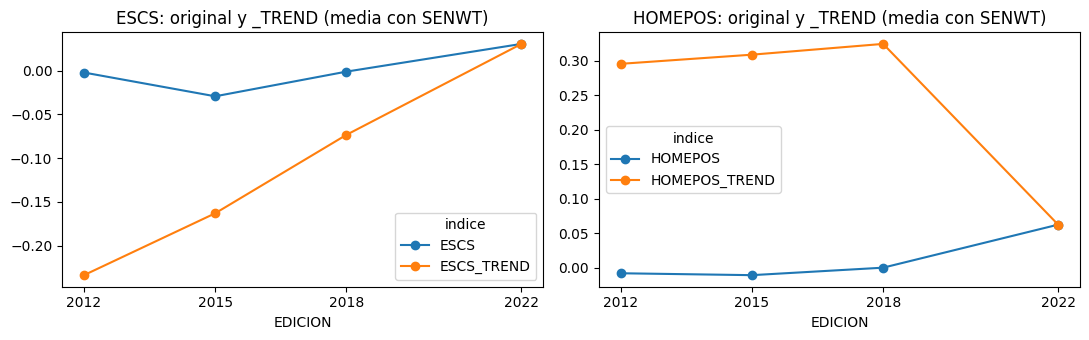

In [13]:
filas = []
for año in EDICIONES:
    est = estudiantes[año]
    for c in ('ESCS', 'HOMEPOS', 'HISEI', 'PAREDINT'):
        for col in (c, f'{c}_TREND'):
            x = est[[col, 'SENWT']].dropna()
            filas.append({'EDICION': año, 'indice': col, 'media': np.average(x[col], weights=x['SENWT'])})
medias_indices = pd.DataFrame(filas).pivot(index='indice', columns='EDICION', values='media')
display(medias_indices.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for c, a in zip(('ESCS', 'HOMEPOS'), ax):
    medias_indices.loc[[c, f'{c}_TREND']].T.plot(marker='o', ax=a, title=f'{c}: original y _TREND (media con SENWT)')
    a.set_xticks(EDICIONES)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_comparativa_original_Vs_Trend.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.6 Estratos publicados por país

Las tablas maestras traen el estrato de muestreo (`STRATUM`) de cada alumno. Algunos países no lo publican en algunas ediciones: todos sus alumnos tienen un único código, acabado en 97 o 99 (por ejemplo `AUT9797` o `ITA97`), aunque la muestra tenga cientos de centros. El país sí estratificó su muestra, pero esa información no está en los ficheros públicos, así que no se puede recuperar. Por esto, y porque el estrato es una pieza del diseño muestral (cada país define los suyos, no son comparables entre países y sus códigos cambian en 2022), el proyecto no trabaja por estrato: los perfiles de centro se definen a mano, con características que sí se pueden comparar entre países y ediciones (`00_Pipeline_generacion_estratos`).

In [14]:
# Estratos distintos por país y edición, en las tablas maestras completas (no en la vista de análisis)
filas_estratos = []
for año in EDICIONES:
    ruta_est, _ = rutas_datos_anuales(RUTA_RAW_BASE, año)
    alumnos = pd.read_parquet(ruta_est, columns=['CNT', 'STRATUM', 'CNTSCHID'])
    alumnos['STRATUM'] = alumnos['STRATUM'].astype(str)
    por_pais = alumnos.groupby('CNT').agg(estratos=('STRATUM', 'nunique'), centros=('CNTSCHID', 'nunique'), alumnos=('STRATUM', 'size'),
                                          codigo_unico=('STRATUM', lambda codigos: codigos.iloc[0] if codigos.nunique() == 1 else ''))
    filas_estratos.append(por_pais.assign(edicion=año).reset_index())
estratos_por_pais = pd.concat(filas_estratos, ignore_index=True)

sin_publicar = estratos_por_pais[estratos_por_pais['estratos'] == 1].sort_values(['CNT', 'edicion']).reset_index(drop=True)
print(f'{len(sin_publicar)} de {len(estratos_por_pais)} países-edición con un solo estrato publicado '
      f'({sin_publicar["CNT"].nunique()} países); códigos: {sorted(sin_publicar["codigo_unico"].unique())}')
print(f'Centros por país-edición en esos casos: de {sin_publicar["centros"].min()} a {sin_publicar["centros"].max()}')
display(sin_publicar[['CNT', 'edicion', 'codigo_unico', 'centros', 'alumnos']])

# Estratos por país y edición: los países que no publican la estratificación en alguna edición
paises_afectados = sorted(sin_publicar['CNT'].unique())
estratos_por_pais.pivot(index='CNT', columns='edicion', values='estratos').loc[paises_afectados]

19 de 132 países-edición con un solo estrato publicado (8 países); códigos: ['AUT97', 'AUT9797', 'BEL9797', 'CAN99', 'DEU97', 'DEU9797', 'ISR97', 'ISR9797', 'ITA97', 'ITA9797', 'NOR97', 'USA9797']
Centros por país-edición en esos casos: de 162 a 863


,CNT,edicion,codigo_unico,centros,alumnos
0,AUT,2012,AUT9797,191,4755
1,AUT,2015,AUT9797,269,7007
2,AUT,2018,AUT9797,291,6802
3,AUT,2022,AUT97,302,6151
4,BEL,2018,BEL9797,288,8475
5,CAN,2022,CAN99,863,23073
6,DEU,2012,DEU9797,230,5001
7,DEU,2015,DEU9797,256,6504
8,DEU,2018,DEU9797,223,5451
9,DEU,2022,DEU97,257,6116


edicion,2012,2015,2018,2022
CNT,,,,
AUT,1,1,1,1
BEL,29,16,1,11
CAN,46,52,58,1
DEU,1,1,1,1
ISR,11,1,1,1
ITA,102,1,1,1
NOR,3,3,2,1
USA,1,1,8,7


**Qué se ve.** 19 de los 132 países-edición (8 países) tienen un solo estrato publicado, con códigos acabados en 97 o 99 (`AUT9797`, `ITA97`, `CAN99`...). No son muestras pequeñas: tienen de 162 a 863 centros. Austria y Alemania no publican sus estratos en ninguna edición. En los demás países depende de la edición: Italia tiene 102 estratos en 2012 y uno solo desde 2015, Israel 11 en 2012 y uno desde 2015, Canadá entre 46 y 58 hasta 2018 y uno en 2022, Bélgica 29, 16 y 11 salvo en 2018, Noruega 2 o 3 hasta 2018 y uno en 2022, y Estados Unidos uno en 2012 y 2015 y 8 y 7 en 2018 y 2022.

## Hallazgos del EDA

* **Nulos por diseño en 2012**: `BELONG`, `ANXMAT`, `MATHEFF`, `TEACHSUP`, `DISCLIMA` y `OUTHOURS` rondan el 35 % por la rotación de cuestionarios; no es no-respuesta.
* **Módulos solo parciales**: en 2022 faltan por completo `ICTRES` en 19 de 33 países y `ICTWKDY`/`ICTWKEND`/`ICTDISTR` en 7. `BEINGBULLIED` tiene un 25 % de nulos en 2018.
* **Centros**: `STAFFSHORT` falta en el 29 % de los centros de 2022 (6 países sin dato); `STRATIO` y `CLSIZE` hasta en el 24 %; `SCHLTYPE` entre el 12 % y el 15 % desde 2015.
* **Índices originales y `_TREND`**: los originales se estandarizan en cada ciclo (media ~0 con `SENWT`). `ESCS_TREND` sube de −0,23 (2012) a +0,03 (2022) y `HISEI_TREND`/`PAREDINT_TREND` también; `HOMEPOS_TREND` (+0,30 a +0,32) no enlaza con `HOMEPOS` de 2022 (+0,06).
* **`HISEI_TREND` 2012**: Austria no tiene ningún valor (el `HISEI` original sí tiene datos).
* **La no-respuesta no es aleatoria** (paso 7 de `eda_edicion`, en la sección 1; nota del dominio principal relativa a la media del país, ponderada con `SENWT`, en los países que tienen la variable): dentro de cada país, los alumnos sin `ESCS` sacan 68,8 puntos menos que los que lo tienen en 2012, 55,1 en 2015, 49,9 en 2018 y 45,0 en 2022, y en los demás índices de contexto la diferencia va de 28,3 a 81,9 puntos según el índice y la edición. En cambio, en las variables con nulos por la rotación de cuestionarios de 2012 la diferencia es de solo 6,9 a 9,7 puntos. Quitar a los alumnos sin dato deja fuera, sobre todo, a alumnos con notas bajas para su país.
* **Estratos no publicados**: 19 de los 132 países-edición (8 países) tienen un solo estrato (código acabado en 97 o 99) aunque sus muestras tienen de 162 a 863 centros: PISA no publica su estratificación. Austria y Alemania en todas las ediciones; Italia e Israel desde 2015; Estados Unidos en 2012 y 2015; Bélgica en 2018; Canadá y Noruega en 2022. Es una de las razones por las que el proyecto no usa el estrato y define a mano perfiles de centro (`00_Pipeline_generacion_estratos`).